# DS2002 Midterm — Walmart Hurricane Analytics

## 0. Environment, inputs and reproducible preprocessing

In [2]:
from pathlib import Path
import sys, subprocess, sqlite3, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display

sns.set_theme(style="whitegrid")
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "walmart_transactions.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open notebook within the cloned ds2002_walmart_hurricane_project repository")
DATA, PROCESSED = ROOT / 'data', ROOT / 'data' / 'processed'
for script in ['clean_pipeline.py', 'build_sku_mapping.py']:
    result = subprocess.run([sys.executable, str(ROOT / 'src' / script)], cwd=ROOT, capture_output=True, text=True)
    print(f'== {script} ==\n{result.stdout}')
    if result.returncode:
        raise RuntimeError(f'{script} failed:\n{result.stderr}')
raw = pd.read_csv(DATA / 'walmart_transactions.csv')
sales = pd.read_csv(PROCESSED / 'transactions_enriched.csv', parse_dates=['timestamp','date'])
stores = pd.read_csv(PROCESSED / 'stores_clean.csv')
catalog = pd.read_csv(DATA / 'product_catalog.csv')
dcs = pd.read_csv(DATA / 'distribution_centers.csv')
log = pd.read_csv(PROCESSED / 'cleaning_decision_log.csv')
print('Raw rows:',len(raw),'Clean rows:',len(sales),'Stores:',sales.store_id.nunique())
display(log)
display(sales.head())

== clean_pipeline.py ==
Raw transactions: 25,562; cleaned positive demand rows: 24,521
Unique stores: 12; date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00
                                         action  rows_affected  rows_removed                                                                               explanation
                  Normalize store IDs in lookup              2             0                                               Standardize FL239, FL_239, fl-239 to FL-239
                       Deduplicate store lookup              2             2                                                Keep first row for each canonical store ID
                       Flag missing coordinates              1             0                      Keep stores with missing coordinates; geocode separately for weather
          Drop exact duplicate transaction rows             30            30 Potential duplicate exports; confirm this policy if identical purchases may be legitimate
    

,action,rows_affected,rows_removed,explanation
0,Normalize store IDs in lookup,2,0,"Standardize FL239, FL_239, fl-239 to FL-239"
1,Deduplicate store lookup,2,2,Keep first row for each canonical store ID
2,Flag missing coordinates,1,0,Keep stores with missing coordinates; geocode ...
3,Drop exact duplicate transaction rows,30,30,Potential duplicate exports; confirm this poli...
4,Normalize transaction store IDs,4345,0,Match canonical IDs in store lookup
5,Remove invalid/missing timestamps,884,884,Unusable for daily hurricane analysis
6,Quarantine missing/invalid prices,0,0,"Do not silently convert missing, text, or nega..."
7,Quarantine missing/zero quantities,0,0,No usable positive unit volume
8,Separate negative quantities (possible returns),127,127,Exclude from gross demand; retain in separate ...
9,Quarantine store IDs missing from lookup,0,0,Prevent unmatched store weather joins


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date,sales_amount,canonical_product,canonical_category
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,2024-09-24,3.15,Peanut Butter,Grocery
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,2024-09-13,2.02,Canned Soup,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,2024-09-17,20.94,Toilet Paper,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,2024-09-11,28.59,Streaming Device,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,2024-09-26,56.46,Light Beer 24-Pack,Alcohol


### Cleaning assumptions and checks
We remove exact duplicates and invalid timestamps; isolate invalid prices, zero/missing quantities and negative quantities (possible returns); normalize store identifiers; and map catalog SKUs to canonical families. **This produces a gross-positive-demand view, not net sales.** Check the rejected rows and whether prices should be required for quantity-based analyses. SKU family totals treat each recorded `quantity` as one package, not equivalent individual units across package sizes.

In [3]:
required = {'store_id','sku','canonical_product','canonical_category','date','quantity','unit_price'}
assert required <= set(sales.columns), required-set(sales.columns)
assert sales['canonical_product'].notna().all(), 'Review unmapped SKU report'
assert sales['quantity'].gt(0).all()
assert sales['store_id'].isin(stores['store_id']).all()
assert not sales['date'].isna().any()
assert len(sales)==len(pd.read_csv(PROCESSED/'transactions_clean.csv')), 'SKU merge duplicated or removed rows'
assert sales['quantity'].sum()==pd.read_csv(PROCESSED/'transactions_clean.csv')['quantity'].sum(), 'SKU merge changed units'
for name in ['unmapped_skus','negative_quantity_returns','invalid_prices','invalid_quantities','unknown_stores']:
    file=PROCESSED/f'{name}.csv'
    if file.exists():
        d=pd.read_csv(file)
        print(f'{name}: {len(d):,} rows')
        if name=='unmapped_skus' and len(d):display(d)
print('Distinct source SKUs:',sales.sku.nunique(),'; canonical products:',sales.canonical_product.nunique())
print('Mapped product families (sample):')
display(sales[['sku','canonical_product','canonical_category']].drop_duplicates().sort_values('canonical_product').head(25))

unmapped_skus: 0 rows
negative_quantity_returns: 127 rows
invalid_prices: 0 rows
invalid_quantities: 0 rows
unknown_stores: 0 rows
Distinct source SKUs: 45 ; canonical products: 20
Mapped product families (sample):


,sku,canonical_product,canonical_category
81,BAT-AA4,AA Batteries,Emergency Supplies
37,BATT-100,AA Batteries,Emergency Supplies
27,BATT_AA_4PK,AA Batteries,Emergency Supplies
50,DIAPERS-3,Baby Diapers Size 3,Baby
48,DIAP-S3,Baby Diapers Size 3,Baby
29,BFORM-01,Baby Formula,Baby
46,BABYFORMULA,Baby Formula,Baby
59,WATER24PK,Bottled Water 24-Pack,Emergency Supplies
30,WTR-24,Bottled Water 24-Pack,Emergency Supplies
175,WTR_24PK,Bottled Water 24-Pack,Emergency Supplies


## 1. Q1 — Demand surge by category

,baseline_units_per_day,surge_units_per_day,multiple,increase_pct
canonical_category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency Supplies,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94


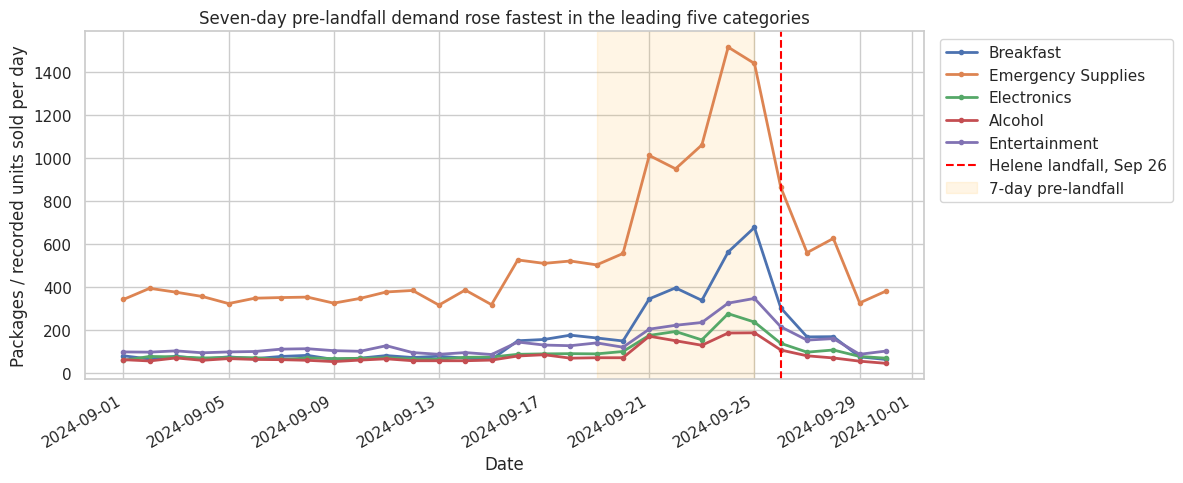

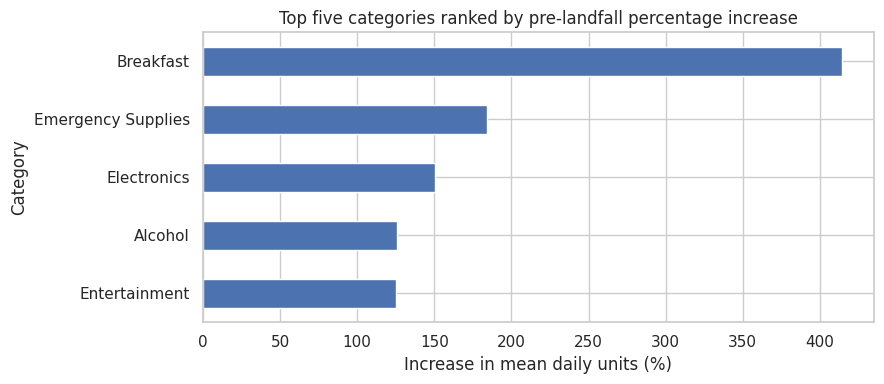

Q1 top category: Breakfast change: 414.4 %


In [4]:
LANDFALL=pd.Timestamp('2024-09-26')
B0,B1=pd.Timestamp('2024-09-01'),pd.Timestamp('2024-09-15')
S0,S1=pd.Timestamp('2024-09-19'),pd.Timestamp('2024-09-25')
full_dates=pd.date_range(B0, pd.Timestamp('2024-09-30'),freq='D')
category_daily=(sales.groupby(['date','canonical_category'])['quantity'].sum().unstack(fill_value=0).reindex(full_dates,fill_value=0))
base=category_daily.loc[B0:B1].mean()
surge=category_daily.loc[S0:S1].mean()
q1=pd.DataFrame({'baseline_units_per_day':base,'surge_units_per_day':surge})
q1['multiple']=np.where(q1.baseline_units_per_day>0,q1.surge_units_per_day/q1.baseline_units_per_day,np.nan)
q1['increase_pct']=(q1['multiple']-1)*100
q1=q1.sort_values('increase_pct',ascending=False)
display(q1.round(2))
top5=q1.head(5).index.tolist()
fig,ax=plt.subplots(figsize=(12,5))
for cat in top5:ax.plot(category_daily.index,category_daily[cat],label=cat,marker='.',linewidth=2)
ax.axvline(LANDFALL,color='red',linestyle='--',label='Helene landfall, Sep 26')
ax.axvspan(S0,S1,color='orange',alpha=.1,label='7-day pre-landfall')
ax.set(title='Seven-day pre-landfall demand rose fastest in the leading five categories',xlabel='Date',ylabel='Packages / recorded units sold per day')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left');fig.autofmt_xdate();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4))
q1.head(5).sort_values('increase_pct')['increase_pct'].plot.barh(ax=ax)
ax.set(title='Top five categories ranked by pre-landfall percentage increase',xlabel='Increase in mean daily units (%)',ylabel='Category');plt.tight_layout();plt.show()
print('Q1 top category:',q1.index[0], 'change:',round(q1.iloc[0].increase_pct,1),'%')

**Q1 finding:** We compared sales during September 19–25 with the September 1–15 baseline. We used average daily units because the periods have different lengths. Before the comparison, we removed duplicate transactions, processed timestamps, and standardized SKUs and categories. We also excluded possible returns from gross sales volume.

Breakfast had the largest percentage increase. Average daily sales rose from 73.27 to 376.86 units, an increase of 414.36%. Emergency Supplies ranked second. Its daily average rose from 354.07 to 1,006.43 units, an increase of 184.25%.

Electronics increased by 150.27%, from 70.27 to 175.86 units per day. Alcohol increased by 125.66%, from 61.53 to 138.86 units. Entertainment increased by 124.97%, from 101.60 to 228.57 units. These were the top five categories by percentage growth.

Breakfast had the strongest proportional growth. Emergency Supplies had the highest pre-landfall volume and the largest absolute increase among the top five. The daily trend chart shows sales for these categories over time. These results can help managers prioritize inventory before future storms. 

## 2. Q2 — Pop-Tarts SKU consolidation

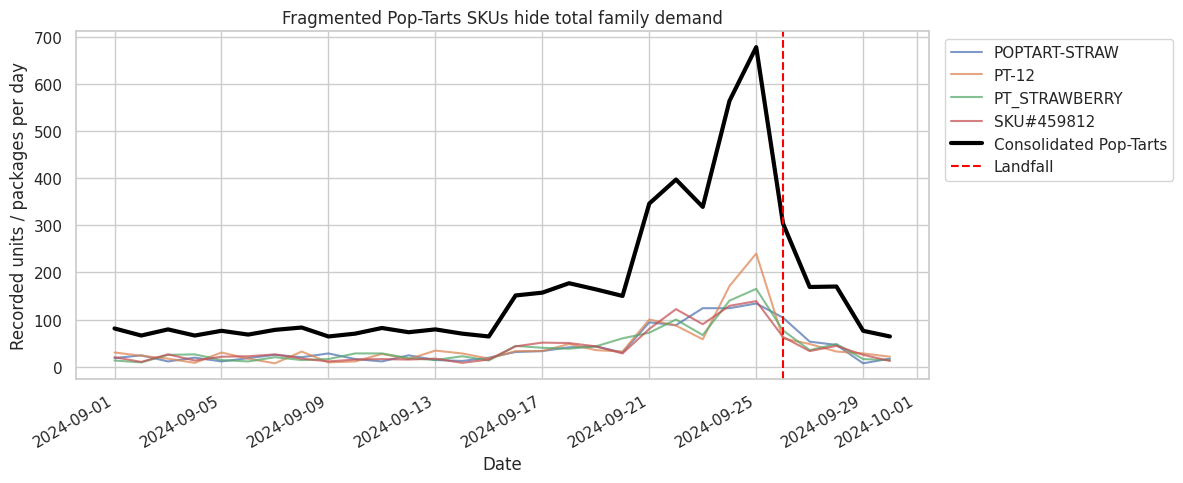

Source SKUs: 4 Consolidated families: 1
Pop-Tarts baseline daily mean: 73.27 Surge mean: 376.86 Multiple: 5.14
Quantity preserved: True


,sku,canonical_product
49,POPTART-STRAW,Pop-Tarts Strawberry
44,PT-12,Pop-Tarts Strawberry
21,PT_STRAWBERRY,Pop-Tarts Strawberry
26,SKU#459812,Pop-Tarts Strawberry


In [5]:
popt=sales[sales.canonical_product.eq('Pop-Tarts Strawberry')].copy()
assert len(popt)>0, 'Check SKU mapping'
pt_sku=popt.groupby(['date','sku'])['quantity'].sum().unstack(fill_value=0).reindex(full_dates,fill_value=0)
pt_total=pt_sku.sum(axis=1)
assert pt_total.sum()==popt.quantity.sum()
fig,ax=plt.subplots(figsize=(12,5))
for sku in pt_sku:ax.plot(pt_sku.index,pt_sku[sku],alpha=.72,label=sku)
ax.plot(pt_total.index,pt_total,color='black',linewidth=3,label='Consolidated Pop-Tarts')
ax.axvline(LANDFALL,color='red',linestyle='--',label='Landfall')
ax.set(title='Fragmented Pop-Tarts SKUs hide total family demand',xlabel='Date',ylabel='Recorded units / packages per day')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left');fig.autofmt_xdate();plt.tight_layout();plt.show()
pt_base=pt_total.loc[B0:B1].mean();pt_surge=pt_total.loc[S0:S1].mean()
pt_multiple=pt_surge/pt_base if pt_base>0 else np.nan
print('Source SKUs:',popt.sku.nunique(),'Consolidated families:',popt.canonical_product.nunique())
print('Pop-Tarts baseline daily mean:',round(pt_base,2),'Surge mean:',round(pt_surge,2),'Multiple:',round(pt_multiple,2))
print('Quantity preserved:',pt_sku.sum().sum()==pt_total.sum())
display(popt[['sku','canonical_product']].drop_duplicates().sort_values('sku'))

**Q2 finding:** Four SKU variants were mapped to one product, Pop-Tarts Strawberry. These were POPTART-STRAW, PT-12, PT_STRAWBERRY, and SKU#459812. Their quantities were added together for each date to show total daily sales.

After consolidation, average daily sales rose from 73.27 units during September 1–15 to 376.86 units during September 19–25. This was a 414.36% increase. Pre-landfall sales were about 5.14 times the baseline level.

The fragmented view splits sales across four identifiers. Each appears to have lower demand than the combined product. The cleaned view shows the full daily volume. Consolidation does not increase total sales. It makes existing demand easier to see.

This clearer view supports better inventory decisions. Managers can order enough stock to meet combined demand. They can also allocate shelf space and forecast sales more accurately. The fragmented view could lead them to underestimate demand and order too little.

## 3. Q3 — Weather integration and lag analysis

Each row is one store, one calendar day, and one category. `units` is the sum of `quantity` for that group. Weather joins on store and date, so every category at a store that day gets the same weather. The charts add units across stores and compare each category with statewide daily weather. The baseline is September 1–15. The surge window is September 19–25, the seven days before landfall.

In [6]:
WEATHER_CACHE=PROCESSED/'weather_daily_open_meteo.csv'
START,END='2024-09-01','2024-09-30'
API='https://archive-api.open-meteo.com/v1/archive'
GEOCODE='https://geocoding-api.open-meteo.com/v1/search'
session=requests.Session()
def get_json(url,params,tries=4):
    for i in range(tries):
        try:
            r=session.get(url,params=params,timeout=25)
            if r.status_code in {429,500,502,503,504}:
                r.raise_for_status()
            r.raise_for_status();return r.json()
        except (requests.RequestException,ValueError):
            if i==tries-1:raise
            time.sleep(2**i)
def find_coords(city):
    obj=get_json(GEOCODE,{'name':city,'count':10,'countryCode':'US'})
    matches=[a for a in obj.get('results',[]) if a.get('admin1')=='Florida' and a.get('name','').casefold()==str(city).casefold()]
    if not matches:raise LookupError(f'No Florida geocode result: {city}')
    return matches[0]['latitude'],matches[0]['longitude']
if WEATHER_CACHE.exists():
    weather=pd.read_csv(WEATHER_CACHE,parse_dates=['date'])
    print('Loaded cached real API output:',WEATHER_CACHE)
else:
    frames=[]
    for st in stores.itertuples(index=False):
        lat,lon=st.latitude,st.longitude
        if pd.isna(lat) or pd.isna(lon):lat,lon=find_coords(st.city)
        payload=get_json(API,{'latitude':lat,'longitude':lon,'start_date':START,'end_date':END,
            'daily':'precipitation_sum,wind_speed_10m_max,pressure_msl_mean',
            'timezone':'America/New_York','wind_speed_unit':'kmh'})
        frame=pd.DataFrame(payload['daily']).rename(columns={'time':'date'})
        frame['store_id']=st.store_id;frame['source']='Open-Meteo historical archive';frame['timezone']='America/New_York'
        frames.append(frame)
    weather=pd.concat(frames,ignore_index=True)
    weather['date']=pd.to_datetime(weather['date'])
    weather.to_csv(WEATHER_CACHE,index=False)
weather['date']=pd.to_datetime(weather['date'])
assert not weather.duplicated(['store_id','date']).any()
print('Weather rows:',len(weather),'Stores:',weather.store_id.nunique(),'Dates:',weather.date.nunique())
print('Weather API:',API)
display(weather.head())

Loaded cached real API output: /content/ds2002_walmart_hurricane_project/data/processed/weather_daily_open_meteo.csv
Weather rows: 360 Stores: 12 Dates: 30
Weather API: https://archive-api.open-meteo.com/v1/archive


,date,precipitation_sum,wind_speed_10m_max,pressure_msl_mean,store_id,source,timezone
0,2024-09-01,6.4,18.7,1014.1,FL-239,Open-Meteo historical archive,America/New_York
1,2024-09-02,22.0,12.7,1014.1,FL-239,Open-Meteo historical archive,America/New_York
2,2024-09-03,32.7,20.6,1015.6,FL-239,Open-Meteo historical archive,America/New_York
3,2024-09-04,21.1,12.6,1017.7,FL-239,Open-Meteo historical archive,America/New_York
4,2024-09-05,20.7,15.2,1017.3,FL-239,Open-Meteo historical archive,America/New_York


_merge
both          3595
left_only        0
right_only       0
category-days with no weather: 0
Rows before/after join: 3595 3595
Grain: store, date, and category. Weather is repeated for each category that day.
Sept 1-15 baseline vs Sept 19-25, units per day:


,baseline_units_per_day,surge_units_per_day,multiple
canonical_category,,,
Breakfast,73.27,376.86,5.14
Emergency Supplies,354.07,1006.43,2.84
Electronics,70.27,175.86,2.50
Alcohol,61.53,138.86,2.26
Entertainment,101.60,228.57,2.25
Health,42.33,95.00,2.24
Household,85.13,176.29,2.07
Grocery,171.07,306.57,1.79
Baby,85.20,133.71,1.57


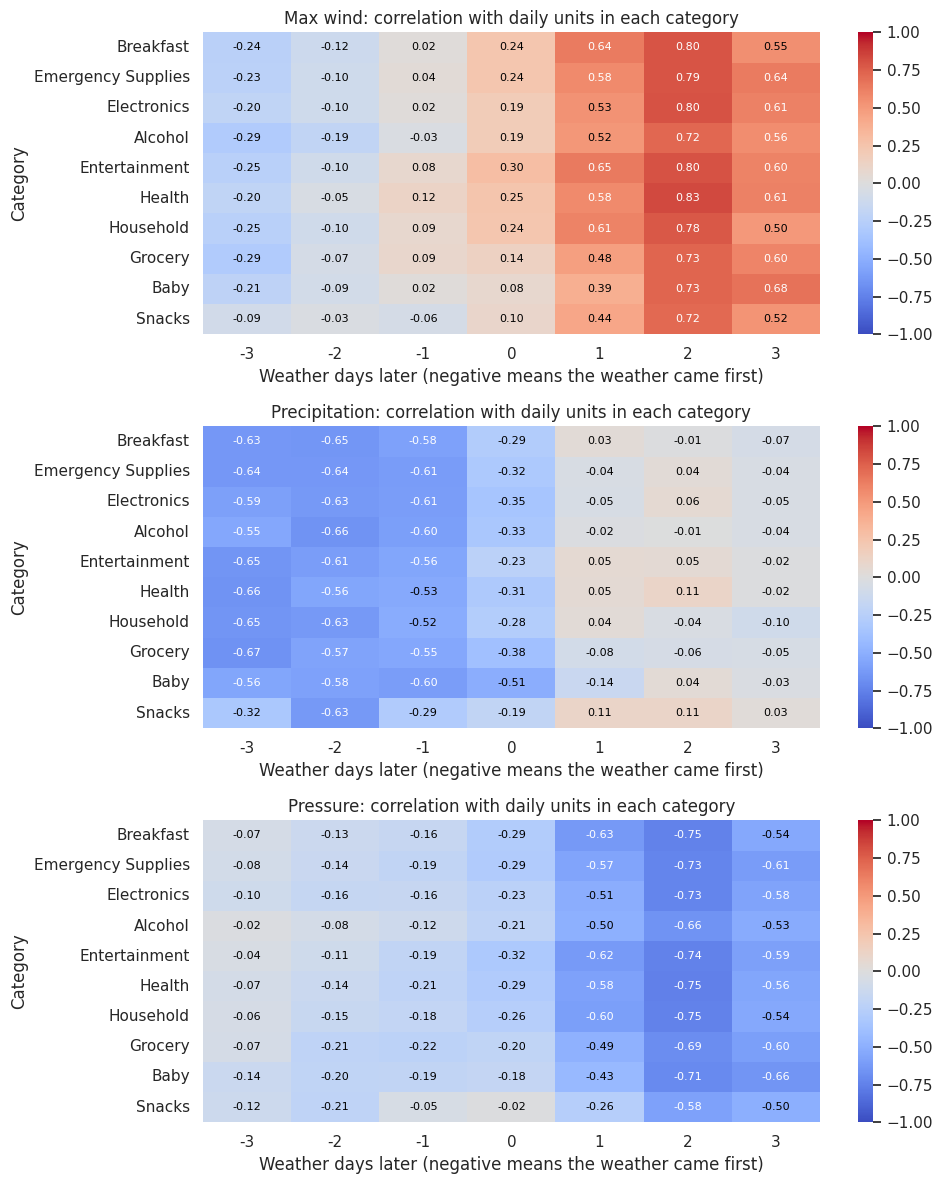

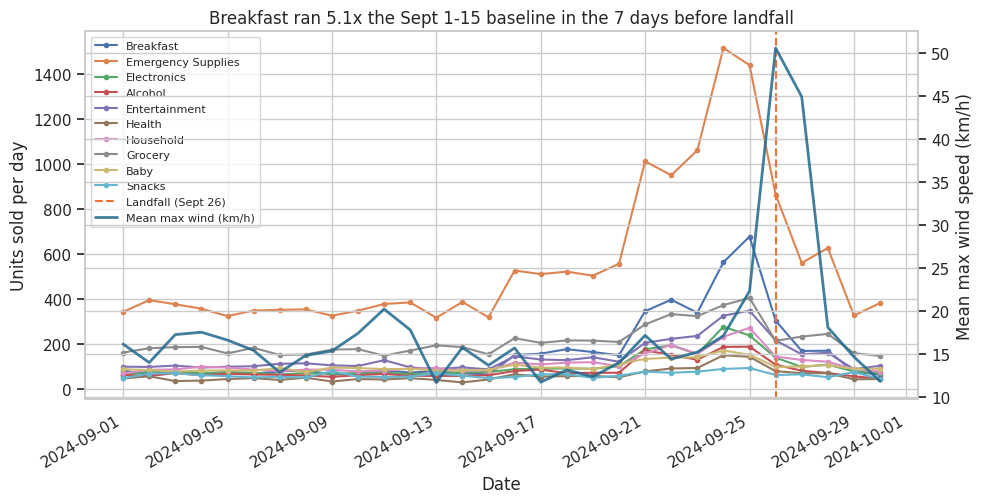

In [7]:
store_cat_day = (
    sales.groupby(['store_id', 'date', 'canonical_category'], as_index=False)
    .agg(units=('quantity', 'sum'))
)
joined = store_cat_day.merge(
    weather, on=['store_id', 'date'], how='left', validate='many_to_one', indicator=True
)
assert len(joined) == len(store_cat_day), 'the join changed the row count'
assert not (joined['_merge'] == 'right_only').any(), 'weather rows with no sales day'
assert joined['units'].sum() == store_cat_day['units'].sum(), 'the units total changed'
print(joined['_merge'].value_counts().to_string())
print('category-days with no weather:', int((joined['_merge'] == 'left_only').sum()))
assert (joined['_merge'] == 'both').all(), 'Review weather dates / store matches'
joined = joined.drop(columns='_merge')
print('Rows before/after join:', len(store_cat_day), len(joined))
print('Grain: store, date, and category. Weather is repeated for each category that day.')

vars_weather = ['wind_speed_10m_max', 'precipitation_sum', 'pressure_msl_mean']
# Average the store-day weather table. Averaging the joined rows would let a category
# with more store rows pull the statewide weather mean.
w_state = weather.groupby('date')[vars_weather].mean().sort_index()
cat_daily = (
    joined.groupby(['date', 'canonical_category'])['units']
    .sum()
    .unstack('canonical_category')
    .fillna(0)
    .sort_index()
)

base = cat_daily.loc[B0:B1].mean()
surge = cat_daily.loc[S0:S1].mean()
by_cat = pd.DataFrame({
    'baseline_units_per_day': base,
    'surge_units_per_day': surge,
})
by_cat['multiple'] = by_cat['surge_units_per_day'] / by_cat['baseline_units_per_day']
by_cat = by_cat.sort_values('multiple', ascending=False)
print('Sept 1-15 baseline vs Sept 19-25, units per day:')
display(by_cat.round(2))

# days_later = 2 pairs today's units with the weather two days later.
lag_rows = []
for cat in cat_daily.columns:
    for var in vars_weather:
        for k in range(-3, 4):
            aligned = pd.concat([cat_daily[cat], w_state[var].shift(-k)], axis=1).dropna()
            lag_rows.append({
                'category': cat,
                'indicator': var,
                'days_later': k,
                'r': aligned.iloc[:, 0].corr(aligned.iloc[:, 1]),
                'n_days': len(aligned),
            })
lag_table = pd.DataFrame(lag_rows)

pretty = {
    'wind_speed_10m_max': 'Max wind',
    'precipitation_sum': 'Precipitation',
    'pressure_msl_mean': 'Pressure',
}
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for ax, var in zip(axes, vars_weather):
    grid = (
        lag_table[lag_table.indicator.eq(var)]
        .pivot(index='category', columns='days_later', values='r')
        .loc[by_cat.index]
    )
    sns.heatmap(grid, cmap='coolwarm', center=0, annot=False, ax=ax, vmin=-1, vmax=1)
    for i, cat in enumerate(grid.index):
        for j, day in enumerate(grid.columns):
            val = grid.loc[cat, day]
            ax.text(
                j + 0.5, i + 0.5, f'{val:.2f}',
                ha='center', va='center', fontsize=8,
                color='white' if abs(val) >= 0.55 else 'black',
            )
    ax.set(
        title=f'{pretty[var]}: correlation with daily units in each category',
        xlabel='Weather days later (negative means the weather came first)',
        ylabel='Category',
    )
plt.tight_layout()
plt.show()

top_name = by_cat.index[0]
top_mult = by_cat.iloc[0]['multiple']
fig, ax = plt.subplots(figsize=(10, 5.2))
for cat in by_cat.index:
    ax.plot(cat_daily.index, cat_daily[cat], marker='o', ms=3, label=cat)
ax.axvline(LANDFALL, color='#F67132', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax2 = ax.twinx()
ax2.plot(
    w_state.index, w_state['wind_speed_10m_max'],
    color='#21688D', alpha=0.85, linewidth=2, label='Mean max wind (km/h)',
)
ax2.set_ylabel('Mean max wind speed (km/h)')
ax.set_title(
    f'{top_name} ran {top_mult:.1f}x the Sept 1-15 baseline in the 7 days before landfall'
)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q3 finding:**
For wind speed, there's a moderate-to-high correlation between wind severity and sales before the wind actually arrives 1-3 days before. For precipitation, it looks like there's a moderate-to-high inverse relationship between severity and sales after the weather has arrived, with very little correlation between severity and sales in the days before rain. Lastly, for pressure, there's a moderate-to-high inverse relationship between sales and pressure that occurs mostly 2 days before a pressure change.

On the line chart, we can see that there is a detectable lag between the weather severity escalation (specifically, Sept 26 when wind spiked and landfall occurred) and the purchasing spike that occurred earlier around Sept 24-25.

## 4. Q4 — Geographic store patterns

Stores are grouped by miles from an approximate Big Bend landfall point (30.00 N, 83.70 W). Magnitude is the September 19–25 daily units divided by the September 1–15 baseline. Timing is the peak day from September 19 through landfall.

,store_id,baseline_daily_units,surge_daily_units,surge_multiple,peak_date,city,latitude,longitude,miles_from_landfall,distance_group
6,FL-330,86.73,235.43,2.71,2024-09-24,Miami,25.76,-80.19,362.80,over 200 miles
10,FL-619,86.13,224.14,2.60,2024-09-24,Tallahassee,30.44,-84.28,46.03,within 100 miles
1,FL-105,91.73,231.71,2.53,2024-09-25,Tampa,27.95,-82.46,160.29,100-200 miles
7,FL-412,89.47,222.86,2.49,2024-09-25,Jacksonville,30.33,-81.66,124.26,100-200 miles
5,FL-302,96.27,239.43,2.49,2024-09-25,Lakeland,28.04,-81.95,171.84,100-200 miles
8,FL-445,94.53,232.00,2.45,2024-09-24,St. Petersburg,27.77,-82.64,167.04,100-200 miles
11,FL-710,93.40,227.86,2.44,2024-09-25,Pensacola,30.42,-87.22,211.99,over 200 miles
4,FL-287,91.07,220.14,2.42,2024-09-25,Kissimmee,28.29,-81.41,181.83,100-200 miles
2,FL-156,94.93,229.14,2.41,2024-09-24,Daytona Beach,29.21,-81.02,169.82,100-200 miles
9,FL-501,92.53,220.57,2.38,2024-09-24,Fort Myers,26.64,-81.87,257.35,over 200 miles


Surge by distance from landfall:


,stores,mean_surge_multiple,earliest_peak,latest_peak
distance_group,,,,
within 100 miles,2,2.49,2024-09-24,2024-09-25
100-200 miles,7,2.43,2024-09-24,2024-09-25
over 200 miles,3,2.51,2024-09-24,2024-09-25


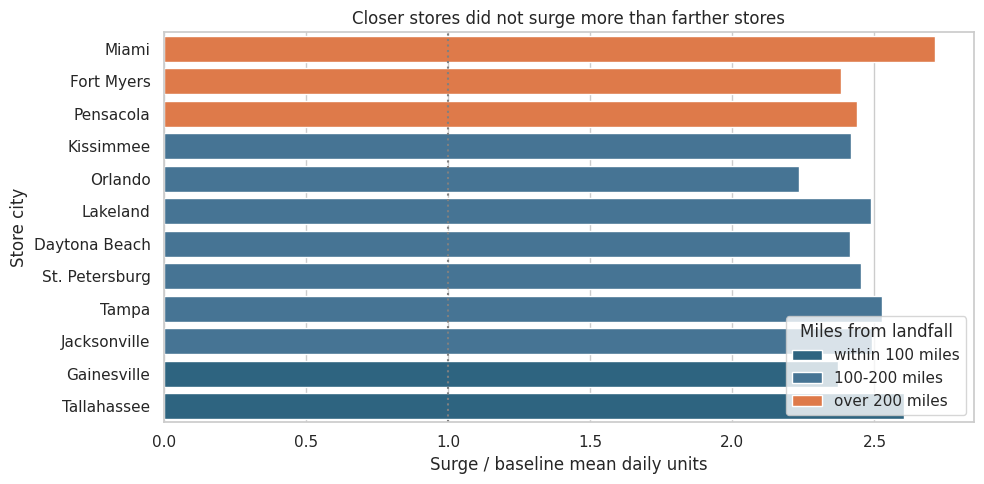

Peak day by store:
          city  peak_date  surge_multiple  miles_from_landfall   distance_group
   Tallahassee 2024-09-24        2.602278            46.033721 within 100 miles
St. Petersburg 2024-09-24        2.454161           167.035553    100-200 miles
 Daytona Beach 2024-09-24        2.413724           169.816291    100-200 miles
       Orlando 2024-09-24        2.234237           172.522852    100-200 miles
    Fort Myers 2024-09-24        2.383697           257.349516   over 200 miles
         Miami 2024-09-24        2.714396           362.796681   over 200 miles
   Gainesville 2024-09-25        2.370130            85.874509 within 100 miles
  Jacksonville 2024-09-25        2.490952           124.256421    100-200 miles
         Tampa 2024-09-25        2.525955           160.290434    100-200 miles
      Lakeland 2024-09-25        2.487139           171.840313    100-200 miles
     Kissimmee 2024-09-25        2.417381           181.825501    100-200 miles
     Pensacola 2024-0

In [8]:
store_days = (
    sales.groupby(['store_id', 'date'])['quantity']
    .sum()
    .unstack('store_id', fill_value=0)
    .reindex(full_dates, fill_value=0)
)
base_store = store_days.loc[B0:B1].mean()
surge_store = store_days.loc[S0:S1].mean()
store_stats = pd.DataFrame({
    'baseline_daily_units': base_store,
    'surge_daily_units': surge_store,
})
store_stats['surge_multiple'] = np.where(
    store_stats.baseline_daily_units > 0,
    store_stats.surge_daily_units / store_stats.baseline_daily_units,
    np.nan,
)
store_stats['peak_date'] = store_days.loc[S0:LANDFALL].idxmax()
store_stats = (
    store_stats.reset_index()
    .merge(stores[['store_id', 'city', 'latitude', 'longitude']], on='store_id', how='left', validate='one_to_one')
)

# FL-619 is blank in the store file. Same Tallahassee lookup used for the weather call.
missing_coords = store_stats['latitude'].isna() | store_stats['longitude'].isna()
store_stats.loc[store_stats['store_id'].eq('FL-619') & missing_coords, ['latitude', 'longitude']] = (30.43826, -84.28073)
LANDFALL_LAT, LANDFALL_LON = 30.00, -83.70

def miles_from_landfall(lat, lon):
    radius = 3958.8
    p1, p2 = np.radians(LANDFALL_LAT), np.radians(lat)
    dphi = np.radians(lat - LANDFALL_LAT)
    dlmb = np.radians(lon - LANDFALL_LON)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * radius * np.arcsin(np.sqrt(a))

store_stats['miles_from_landfall'] = miles_from_landfall(store_stats['latitude'], store_stats['longitude'])
store_stats['distance_group'] = pd.cut(
    store_stats['miles_from_landfall'],
    bins=[0, 100, 200, 1000],
    labels=['within 100 miles', '100-200 miles', 'over 200 miles'],
)
store_stats = store_stats.sort_values('surge_multiple', ascending=False)
display(store_stats.round(2))

geo = store_stats.groupby('distance_group', observed=True).agg(
    stores=('store_id', 'count'),
    mean_surge_multiple=('surge_multiple', 'mean'),
    earliest_peak=('peak_date', 'min'),
    latest_peak=('peak_date', 'max'),
)
print('Surge by distance from landfall:')
display(geo.round(2))

chart = store_stats.sort_values('miles_from_landfall')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=chart,
    x='surge_multiple',
    y='city',
    hue='distance_group',
    hue_order=['within 100 miles', '100-200 miles', 'over 200 miles'],
    order=chart['city'].tolist(),
    dodge=False,
    ax=ax,
    palette={'within 100 miles': '#21688D', '100-200 miles': '#3976a1', 'over 200 miles': '#F67132'},
)
ax.axvline(1, color='gray', linestyle=':')
ax.invert_yaxis()
ax.set(
    title='Closer stores did not surge more than farther stores',
    xlabel='Surge / baseline mean daily units',
    ylabel='Store city',
)
ax.legend(title='Miles from landfall', loc='lower right')
plt.tight_layout()
plt.show()

print('Peak day by store:')
print(
    store_stats.sort_values(['peak_date', 'miles_from_landfall'])[
        ['city', 'peak_date', 'surge_multiple', 'miles_from_landfall', 'distance_group']
    ].to_string(index=False)
)

q1, q3 = store_stats['surge_multiple'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = store_stats.loc[~store_stats['surge_multiple'].between(lo, hi)].copy()
print(f'Outlier rule: surge multiple outside {lo:.2f} to {hi:.2f} (1.5 IQR).')
if outliers.empty:
    print('No outlier stores.')
else:
    print(outliers[['store_id', 'city', 'surge_multiple', 'miles_from_landfall', 'peak_date']].round(2).to_string(index=False))


**Q4 finding:**
From the chart, we can see that all the Florida store locations experience roughly the same surge at the same peak timings (Sept 24 and Sept 25) regardless of distance.

In terms of outliers, using the 1.5 IQR rule, which gives a multiple range from 2.27 to 2.64, we can see that there are two outliers: Miami (FL-330) with a 2.71 surge multiple and Orlando (FL-239) with a 2.23 surge multiple.

## 5. Q5 — Board games signal or artifact (SQLite)

In [9]:
DB=DATA/'inventory_and_sales.db'
con=sqlite3.connect(DB)
try:
    table_names=pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",con)['name'].tolist()
    print('SQLite tables:',table_names)
    sqlite_tables={}
    for table in table_names:
        if table not in ['daily_sales_summary','inventory_levels']:continue
        cols=pd.read_sql_query(f'PRAGMA table_info("{table}")',con)
        print('\n',table,'columns:');display(cols[['name','type']])
        d=pd.read_sql_query(f'SELECT * FROM "{table}"',con)
        sqlite_tables[table]=d
        print('Rows:',len(d));display(d.head())
finally:con.close()
assert 'daily_sales_summary' in sqlite_tables and 'inventory_levels' in sqlite_tables

SQLite tables: ['daily_sales_summary', 'inventory_levels']

 daily_sales_summary columns:


,name,type
0,date,TEXT
1,store_id,TEXT
2,category,TEXT
3,total_units,REAL
4,total_revenue,REAL


Rows: 3600


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30



 inventory_levels columns:


,name,type
0,date,TEXT
1,store_id,TEXT
2,sku,TEXT
3,units_on_hand,INTEGER
4,units_on_order,INTEGER
5,reorder_point,INTEGER


Rows: 4320


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


Entertainment products and units:


,size,sum
canonical_product,,
Playing Cards,1153,2312
Monopoly Board Game,1282,1938


,series,baseline_daily_units,surge_daily_units,increase_pct
0,Entertainment total,101.60,228.57,124.97
1,Monopoly board game,42.87,111.43,159.94


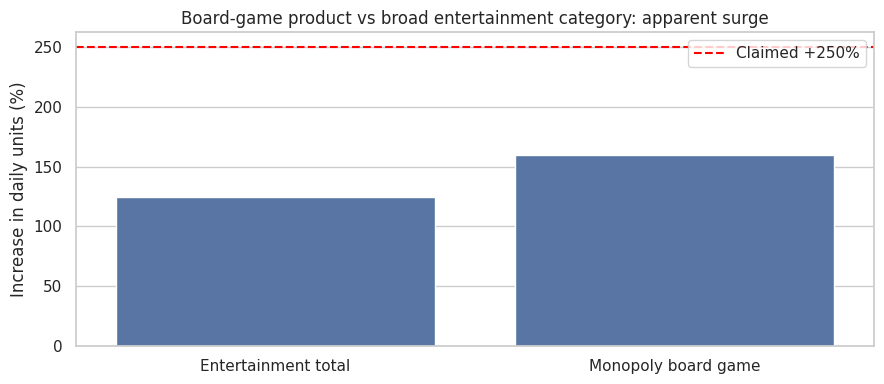


daily_sales_summary: 360 relevant-looking records (of 3600 total)


,date,store_id,category,total_units,total_revenue
3,2024-09-12,FL-239,Entertainment,53.0,916.56
13,2024-09-12,FL-105,Entertainment,62.0,1081.91
23,20240912,FL-330,Entertainment,21.0,192.86
33,2024-09-12,FL-412,Entertainment,26.0,445.07
43,2024-09-12,FL-287,Entertainment,66.0,933.55
53,2024-09-12,FL-156,Entertainment,49.0,623.30
63,2024-09-12,FL-501,Entertainment,77.0,1317.32
73,2024-09-12,FL-078,Entertainment,77.0,1091.91
83,2024-09-12,FL-619,Entertainment,46.0,256.16
93,20240912,FL-445,Entertainment,54.0,883.90



inventory_levels: 536 relevant-looking records (of 4320 total)


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
26,2024-09-12,FL-330,MONOPOLY-01,178,39.0,45
30,2024-09-12,FL-330,BG-MONO,86,38.0,42
44,2024-09-12,FL-412,PLAYCARD-STD,52,8.0,29
52,2024-09-12,FL-287,CARDS-01,142,94.0,22
60,2024-09-12,FL-156,PLAYCARD-STD,181,26.0,45
65,2024-09-12,FL-156,BG-MONO,81,21.0,50
68,2024-09-12,FL-156,STREAM-01,135,94.0,22
69,2024-09-12,FL-156,CARDS-01,141,25.0,42
72,2024-09-12,FL-501,STREAM-01,107,86.0,40
77,2024-09-12,FL-501,MONOPOLY-01,171,10.0,32


IMPORTANT: compare DB daily_sales_summary with transactions by matching date, store and SKU/category keys,
then examine inventory levels around the spike. The table schema above determines the exact SQL.


In [10]:
# transaction-level independent check: board games versus entire Entertainment category
ent=sales[sales.canonical_category.eq('Entertainment')].copy()
board=sales[sales.canonical_product.eq('Monopoly Board Game')].copy()
print('Entertainment products and units:')
display(ent.groupby('canonical_product')['quantity'].agg(['size','sum']).sort_values('sum',ascending=False))
def period_stats(frame,label):
    daily=frame.groupby('date')['quantity'].sum().reindex(full_dates,fill_value=0)
    a=daily.loc[B0:B1].mean();z=daily.loc[S0:S1].mean()
    return {'series':label,'baseline_daily_units':a,'surge_daily_units':z,'increase_pct':100*(z/a-1) if a else np.nan}
q5_compare=pd.DataFrame([period_stats(ent,'Entertainment total'),period_stats(board,'Monopoly board game')])
display(q5_compare.round(2))
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=q5_compare,x='series',y='increase_pct',ax=ax)
ax.axhline(250,color='red',linestyle='--',label='Claimed +250%')
ax.set(title='Board-game product vs broad entertainment category: apparent surge',xlabel='',ylabel='Increase in daily units (%)');ax.legend();plt.tight_layout();plt.show()

for name,df in sqlite_tables.items():
    fields=[c for c in df.columns if any(x in c.lower() for x in ['category','product','sku','item'])]
    matches=pd.Series(False,index=df.index)
    for c in fields: matches |= df[c].astype(str).str.contains('board|game|mono|entertain|card|stream',case=False,regex=True,na=False)
    hits=df.loc[matches]
    print(f'\n{name}: {len(hits)} relevant-looking records (of {len(df)} total)')
    display(hits.head(25))
print('IMPORTANT: compare DB daily_sales_summary with transactions by matching date, store and SKU/category keys,')
print('then examine inventory levels around the spike. The table schema above determines the exact SQL.')

**Q5 evidence-based conclusion:** The surge in board games and entertainment is a real demand signa;, but the claim of +250% surge in sales within the board-games/entertainment category is unsupported by the transaction level data. Entertainment as a whole, experienced a surge of approximately +125%, while Monopoly alone observed a surge of approximately +159%, both well below the claimed increase.


Without Monopoly included in the entertainment category significant growth of about +99% still exists, meaning products such as playing cards and streaming devices are demanded at a higher rate during storm preparation. We would recommend that entertainment products are stocked at a greater rate in preparation of the next storm, about 2.5X the current amount, and Monopoly specifically is stocked at an even higher rate of about 3X, to manage increased demand. We recommend against using +250% for planning. We also recommend a single SKU master table and a reconciliation check between the transaction, summary and inventory systems, so a figure like this can be traced to its source in the future.


## 6. Business takeaways and reflection